In [21]:
import pandas as pd
import numpy as np

df = pd.read_csv("clean_final_data.csv")

# rows and columns 
print(df.shape)

#rows
print(df.shape[0])

#columns
print(df.shape[1])
print(df.columns)

#data types
print(df.dtypes)

#missing values
missing = df.isnull().sum()
print(missing)

#duplicates
duplicates = df.duplicated().sum()
print(duplicates)

print(df["OrderID"].duplicated().sum())

#logical values

print(f"negative quantities: {(df["Quantity"] < 0).sum()}")
print(f"negative sales: {(df["Sales"] < 0).sum()}")
print(f"Negative OrderValue: {(df['OrderValue'] < 0).sum()}")
print(f"Discount > 100%: {(df['Discount'] > 100).sum()}")
print(f"Discount < 0%: {(df['Discount'] < 0).sum()}")
print(f"Age < 18 or Age > 100: {((df['Age'] < 18) | (df['Age'] > 100)).sum()}")
print(f"UnitPrice <= 0: {(df['UnitPrice'] <= 0).sum()}")

#business logic
df['Expected_Sales'] = df['Quantity'] * df['UnitPrice'] * (1 - df['Discount']/100)

df['Sales_Match'] = np.isclose(df['Sales'], df['Expected_Sales'], atol=0.5)
mismatches = df[~df['Sales_Match']]
print(f"Rows where Sales ≠ Quantity × UnitPrice × (1-Discount): {len(mismatches)}")
if len(mismatches) > 0:
    print("\nSample mismatches:")
    print(mismatches[['OrderID','Quantity','UnitPrice','Discount','Sales','Expected_Sales']].head())

#date logic

df['OrderDate_dt'] = pd.to_datetime(df['OrderDate'])
df['SignupDate_dt'] = pd.to_datetime(df['SignupDate'])
future_orders = df[df['OrderDate_dt'] > pd.Timestamp('2026-09-22')]  # today's date
past_signups = df[df['SignupDate_dt'] > df['OrderDate_dt']]  # signed up AFTER ordering?!
print(f"Orders in the future (after Sep 22, 2026): {len(future_orders)}")
print(f"Customers who signed up AFTER their first order: {len(past_signups)}")

#status vs sales alignment
cancelled_with_sales = df[(df['Status'] == 'Cancelled') & (df['Sales'] > 0)]
returned_with_sales = df[(df['Status'] == 'Returned') & (df['Sales'] > 0)]
completed_no_sales = df[(df['Status'] == 'Completed') & (df['Sales'] <= 0)]
print(f"Cancelled orders with POSITIVE sales: {len(cancelled_with_sales)}")
print(f"Returned orders with POSITIVE sales: {len(returned_with_sales)}")
print(f"Completed orders with ZERO/NEGATIVE sales: {len(completed_no_sales)}")

#OUTLIER DETECTION (Statistical)
print("Age distribution:")
print(df['Age'].describe())
print(f"Top 5 highest OrderValues:")
print(df.nlargest(5, 'OrderValue')[['OrderID','ProductName','Quantity','UnitPrice','OrderValue']])

#CATEGORICAL CONSISTENCY

print("Unique Status values:", df['Status'].unique())
print("Unique PaymentMethod:", df['PaymentMethod'].unique())
print("Unique CustomerSegment:", df['CustomerSegment'].unique())
print("Unique Category:", df['Category'].unique())

(49222, 17)
49222
17
Index(['OrderID', 'CustomerID', 'OrderDate', 'ProductID', 'Quantity',
       'Discount', 'PaymentMethod', 'Status', 'Age', 'City', 'SignupDate',
       'CustomerSegment', 'ProductName', 'Category', 'UnitPrice', 'Sales',
       'OrderValue'],
      dtype='str')
OrderID              int64
CustomerID           int64
OrderDate              str
ProductID            int64
Quantity           float64
Discount           float64
PaymentMethod          str
Status                 str
Age                float64
City                   str
SignupDate             str
CustomerSegment        str
ProductName            str
Category               str
UnitPrice          float64
Sales              float64
OrderValue         float64
dtype: object
OrderID            0
CustomerID         0
OrderDate          0
ProductID          0
Quantity           0
Discount           0
PaymentMethod      0
Status             0
Age                0
City               0
SignupDate         0
CustomerSegmen

In [22]:
# data cleaning

# convert dates

df["OrderDate"] = pd.to_datetime(df["OrderDate"])
df["SignupDate"] = pd.to_datetime(df["SignupDate"])

#drop exact duplicate rows
df = df.drop_duplicates()

#drop duplicate order Ids(keep first)

df = df.drop_duplicates(subset=["OrderID"], keep="first")

# Handle negative quantities/ sales(treat as anomalies - drop)

df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# fix impossible ages

df = df[(df["Age"] >= 18) & (df["Age"] <= 100)]

#fix age logic - drop orders before sign up

df = df[df['OrderDate'] >= df['SignupDate']]

#Standardize categorical values

df['Status'] = df['Status'].str.strip().str.title()
df['PaymentMethod'] = df['PaymentMethod'].str.strip().str.title()
df['CustomerSegment'] = df['CustomerSegment'].str.strip().str.title()

# Handle Cancelled/Returned orders for revenue calc
# Create a "Net_Revenue" column: only Completed orders count
df['Net_Revenue'] = np.where(df['Status'] == 'Completed', df['Sales'], 0)

# Recalculate Sales to ensure consistency
df['Sales_Calculated'] = df['Quantity'] * df['UnitPrice'] * (1 - df['Discount']/100)

# If mismatch > 1%, flag it
df['Sales_Flag'] = ~np.isclose(df['Sales'], df['Sales_Calculated'], atol=0.5)


# 10. Handle missing values (if any)
df['Age'] = df['Age'].fillna(df['Age'].median())
df['City'] = df['City'].fillna('Unknown')

print(df.info())

<class 'pandas.DataFrame'>
Index: 35431 entries, 0 to 49219
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   OrderID           35431 non-null  int64         
 1   CustomerID        35431 non-null  int64         
 2   OrderDate         35431 non-null  datetime64[us]
 3   ProductID         35431 non-null  int64         
 4   Quantity          35431 non-null  float64       
 5   Discount          35431 non-null  float64       
 6   PaymentMethod     35431 non-null  str           
 7   Status            35431 non-null  str           
 8   Age               35431 non-null  float64       
 9   City              35431 non-null  str           
 10  SignupDate        35431 non-null  datetime64[us]
 11  CustomerSegment   35431 non-null  str           
 12  ProductName       35431 non-null  str           
 13  Category          35431 non-null  str           
 14  UnitPrice         35431 non-null  floa

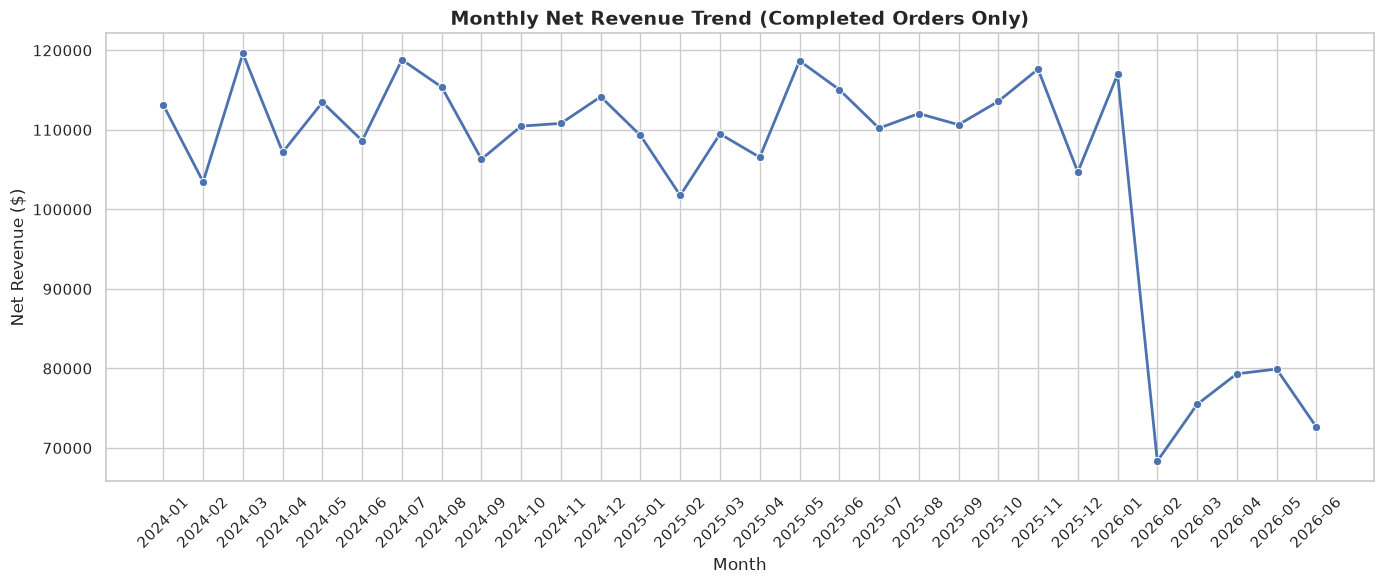

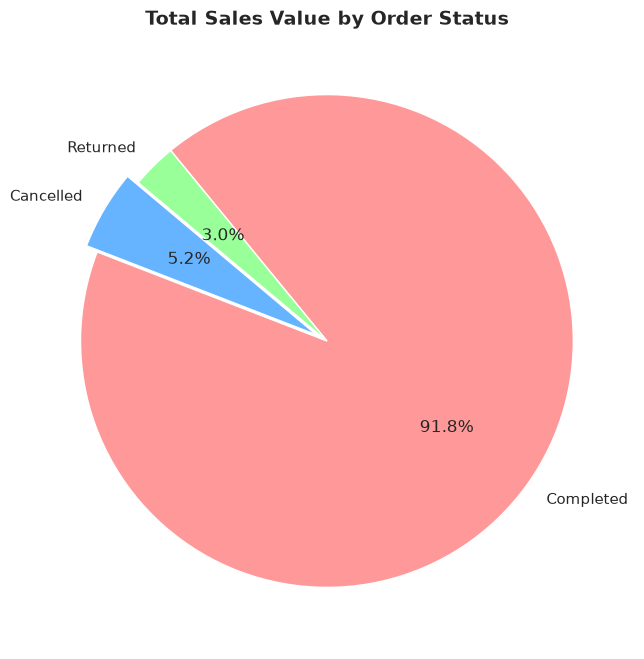

/tmp/ipykernel_18120/3268822747.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=discount_impact.index, y=discount_impact['Completion_Rate'], palette='Blues_r')


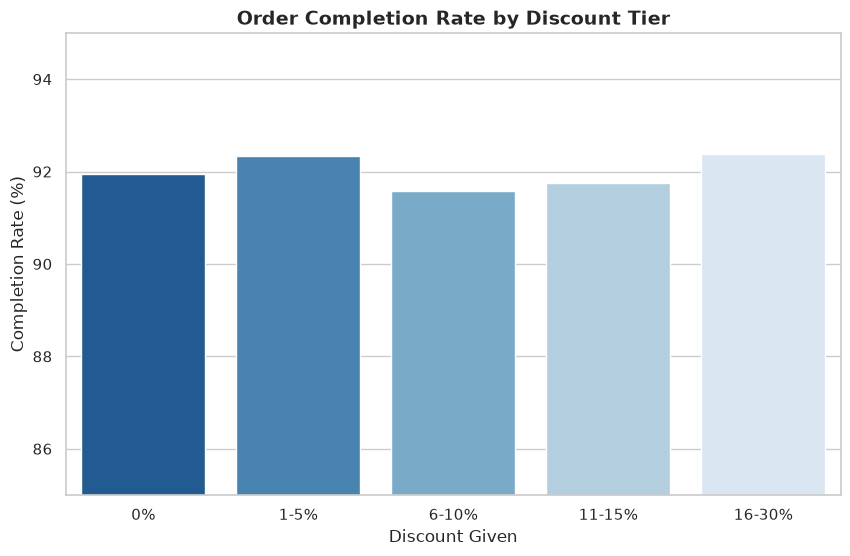

/tmp/ipykernel_18120/3268822747.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=aov_status, x='Status', y='Sales', palette='viridis')


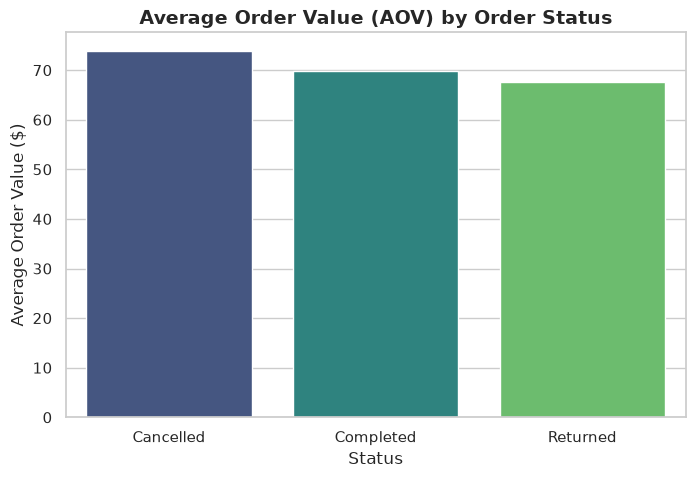

--- RAW NUMBERS FOR YOUR REPORT ---

1. Top 3 Months by Revenue:
YearMonth  Net_Revenue
  2024-03     119603.0
  2024-07     118815.0
  2025-05     118679.0

2. Revenue by Status:
   Status     Sales
Cancelled  180191.0
Completed 3163764.0
 Returned  101815.0

3. Discount Impact Data:
Status        Total_Orders  Completed  Completion_Rate
Discount_Bin                                          
0%                   17342      15944             91.9
1-5%                 10687       9868             92.3
6-10%                 9822       8995             91.6
11-15%                5908       5421             91.8
16-30%                5439       5025             92.4

4. Average Order Value by Status:
   Status  Sales
Cancelled  73.94
Completed  69.91
 Returned  67.52


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD & QUICK CLEAN (Ensures we are analyzing clean data)
df = pd.read_csv('clean_final_data.csv')
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

# Remove impossible orders and create Net Revenue (only Completed orders count)
df = df[df['Quantity'] > 0].copy()
df['Net_Revenue'] = np.where(df['Status'] == 'Completed', df['Sales'], 0.0)

# Set up plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# ==========================================
# ANALYSIS A: Monthly Net Revenue Trend
# ==========================================
df['YearMonth'] = df['OrderDate'].dt.to_period('M').astype(str)
monthly_revenue = df.groupby('YearMonth')['Net_Revenue'].sum().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_revenue, x='YearMonth', y='Net_Revenue', marker='o', color='b', linewidth=2)
plt.title('Monthly Net Revenue Trend (Completed Orders Only)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Net Revenue ($)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==========================================
# ANALYSIS B: Revenue Breakdown by Status
# ==========================================
status_revenue = df.groupby('Status')['Sales'].sum().reset_index()

plt.figure(figsize=(8, 8))
plt.pie(status_revenue['Sales'], labels=status_revenue['Status'], autopct='%1.1f%%', 
        startangle=140, colors=['#66b3ff', '#ff9999', '#99ff99'], explode=(0.05, 0, 0))
plt.title('Total Sales Value by Order Status', fontsize=14, fontweight='bold')
plt.show()

# ==========================================
# ANALYSIS C: Discount Impact on Completion Rate
# ==========================================
# Bin the discounts into logical groups
bins = [-1, 0, 5, 10, 15, 30]
labels = ['0%', '1-5%', '6-10%', '11-15%', '16-30%']
df['Discount_Bin'] = pd.cut(df['Discount'], bins=bins, labels=labels)

# Calculate completion rate per discount bin
discount_impact = df.groupby(['Discount_Bin', 'Status']).size().unstack(fill_value=0)
discount_impact['Total_Orders'] = discount_impact.sum(axis=1)
discount_impact['Completion_Rate'] = (discount_impact['Completed'] / discount_impact['Total_Orders']) * 100

plt.figure(figsize=(10, 6))
sns.barplot(x=discount_impact.index, y=discount_impact['Completion_Rate'], palette='Blues_r')
plt.title('Order Completion Rate by Discount Tier', fontsize=14, fontweight='bold')
plt.xlabel('Discount Given', fontsize=12)
plt.ylabel('Completion Rate (%)', fontsize=12)
plt.ylim(85, 95) # Zoom in to see the subtle differences
plt.show()

# ==========================================
# ANALYSIS D: Average Order Value (AOV) by Status
# ==========================================
aov_status = df.groupby('Status')['Sales'].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=aov_status, x='Status', y='Sales', palette='viridis')
plt.title('Average Order Value (AOV) by Order Status', fontsize=14, fontweight='bold')
plt.xlabel('Status', fontsize=12)
plt.ylabel('Average Order Value ($)', fontsize=12)
plt.show()

# Print the raw numbers for your report
print("--- RAW NUMBERS FOR YOUR REPORT ---")
print("\n1. Top 3 Months by Revenue:")
print(monthly_revenue.nlargest(3, 'Net_Revenue').to_string(index=False))

print("\n2. Revenue by Status:")
print(status_revenue.to_string(index=False))

print("\n3. Discount Impact Data:")
print(discount_impact[['Total_Orders', 'Completed', 'Completion_Rate']].round(1).to_string())

print("\n4. Average Order Value by Status:")
print(aov_status.round(2).to_string(index=False))

📊 1. CUSTOMER SEGMENT OVERVIEW
CustomerSegment  Total_Orders  Total_Revenue  Avg_Order_Value  Revenue_Percent
            New         17049      1101832.0            70.18            34.83
        Regular         27282      1754832.0            70.20            55.47
            VIP          4867       307100.0            68.63             9.71


/tmp/ipykernel_18120/3952955487.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_stats, x='CustomerSegment', y='Total_Revenue', palette='viridis')


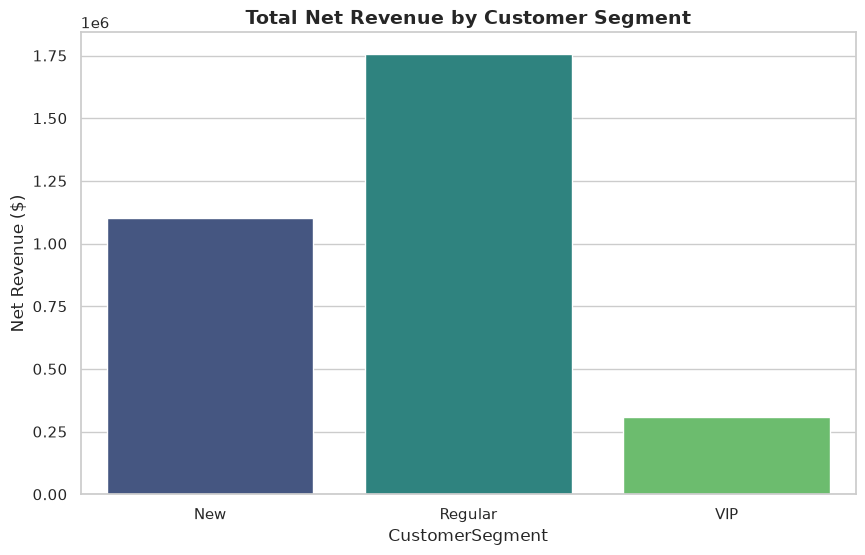


🔄 2. PURCHASE FREQUENCY BY SEGMENT
CustomerSegment  Unique_Customers  Total_Orders  Avg_Orders_Per_Customer
            New              3399         17049                     5.02
        Regular              5468         27282                     4.99
            VIP               953          4867                     5.11

🏆 3. TOP REVENUE CATEGORY PER SEGMENT
CustomerSegment    Category  Net_Revenue
            New Electronics     566281.0
        Regular Electronics     881234.0
            VIP Electronics     154480.0


/tmp/ipykernel_18120/3952955487.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='CustomerSegment', y='Age', palette='pastel', order=['New', 'Regular', 'VIP'])


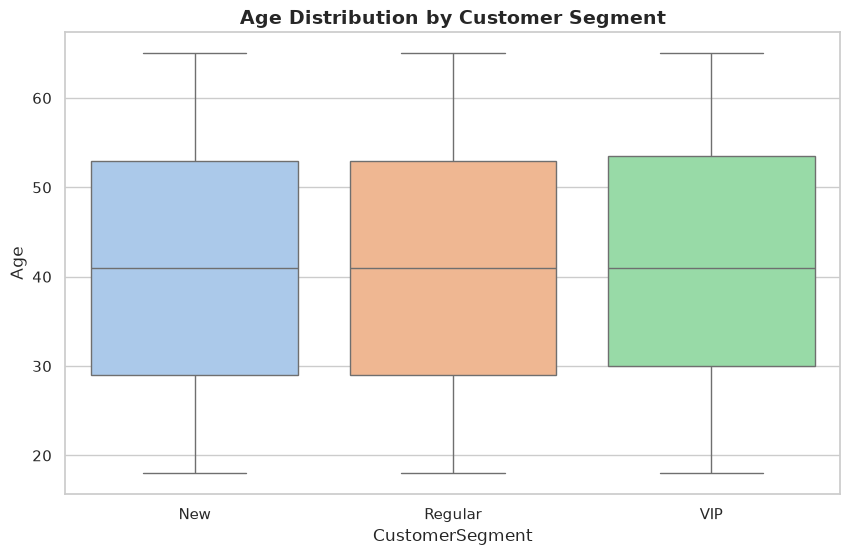


✅ Topic 2 Analysis Complete!


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD & QUICK CLEAN
df = pd.read_csv('clean_final_data.csv')
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df = df[df['Quantity'] > 0].copy()
df['Net_Revenue'] = np.where(df['Status'] == 'Completed', df['Sales'], 0.0)

sns.set_theme(style="whitegrid")

# ==========================================
# ANALYSIS A: Segment Overview (Volume & Value)
# ==========================================
segment_stats = df.groupby('CustomerSegment').agg(
    Total_Orders=('OrderID', 'count'),
    Total_Revenue=('Net_Revenue', 'sum'),
    Avg_Order_Value=('Sales', 'mean')
).reset_index()

# Calculate percentage of total revenue
total_rev = segment_stats['Total_Revenue'].sum()
segment_stats['Revenue_Percent'] = (segment_stats['Total_Revenue'] / total_rev) * 100

print("="*50)
print("📊 1. CUSTOMER SEGMENT OVERVIEW")
print("="*50)
print(segment_stats.round(2).to_string(index=False))

# Plot: Revenue Contribution by Segment
plt.figure(figsize=(10, 6))
sns.barplot(data=segment_stats, x='CustomerSegment', y='Total_Revenue', palette='viridis')
plt.title('Total Net Revenue by Customer Segment', fontsize=14, fontweight='bold')
plt.ylabel('Net Revenue ($)')
plt.show()

# ==========================================
# ANALYSIS B: Purchase Frequency (Loyalty)
# ==========================================
freq_stats = df.groupby('CustomerSegment').agg(
    Unique_Customers=('CustomerID', 'nunique'),
    Total_Orders=('OrderID', 'count')
).reset_index()
freq_stats['Avg_Orders_Per_Customer'] = freq_stats['Total_Orders'] / freq_stats['Unique_Customers']

print("\n" + "="*50)
print("🔄 2. PURCHASE FREQUENCY BY SEGMENT")
print("="*50)
print(freq_stats.round(2).to_string(index=False))

# ==========================================
# ANALYSIS C: Category Preference by Segment
# ==========================================
# What does each segment spend the most money on?
segment_category = df[df['Status'] == 'Completed'].groupby(['CustomerSegment', 'Category'])['Net_Revenue'].sum().reset_index()

# Find the top revenue-generating category for each segment
top_categories = segment_category.loc[segment_category.groupby('CustomerSegment')['Net_Revenue'].idxmax()]

print("\n" + "="*50)
print("🏆 3. TOP REVENUE CATEGORY PER SEGMENT")
print("="*50)
print(top_categories[['CustomerSegment', 'Category', 'Net_Revenue']].round(2).to_string(index=False))

# ==========================================
# ANALYSIS D: Age Distribution by Segment
# ==========================================
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='CustomerSegment', y='Age', palette='pastel', order=['New', 'Regular', 'VIP'])
plt.title('Age Distribution by Customer Segment', fontsize=14, fontweight='bold')
plt.ylabel('Age')
plt.show()

print("\n✅ Topic 2 Analysis Complete!")

/tmp/ipykernel_18120/275731234.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=city_revenue, x='City', y='Net_Revenue', palette='mako')


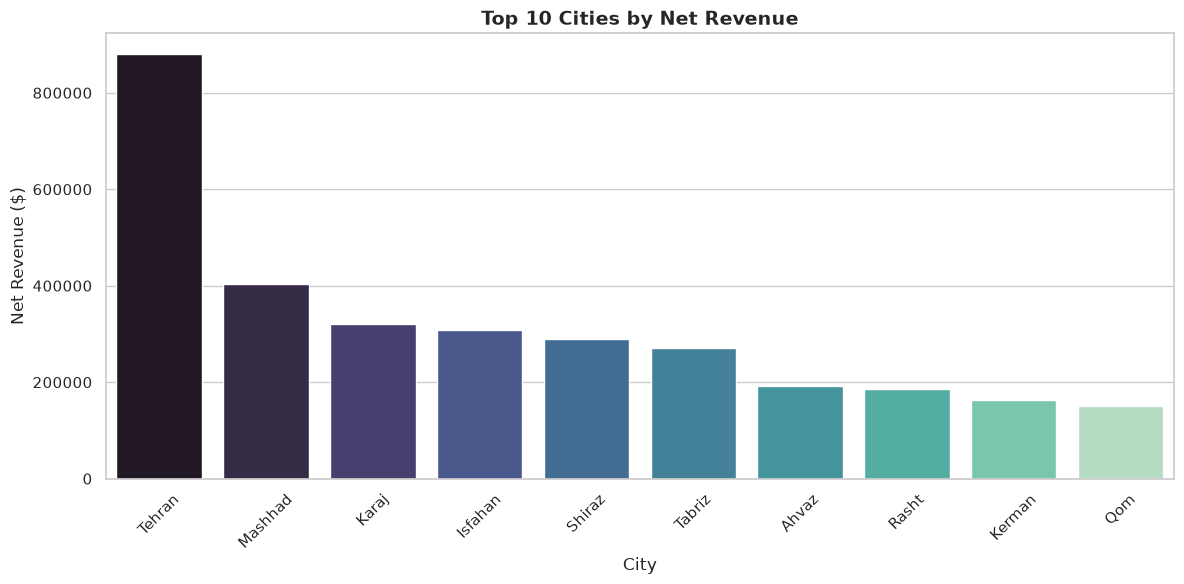

/tmp/ipykernel_18120/275731234.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_revenue, x='Category', y='Net_Revenue', palette='viridis')


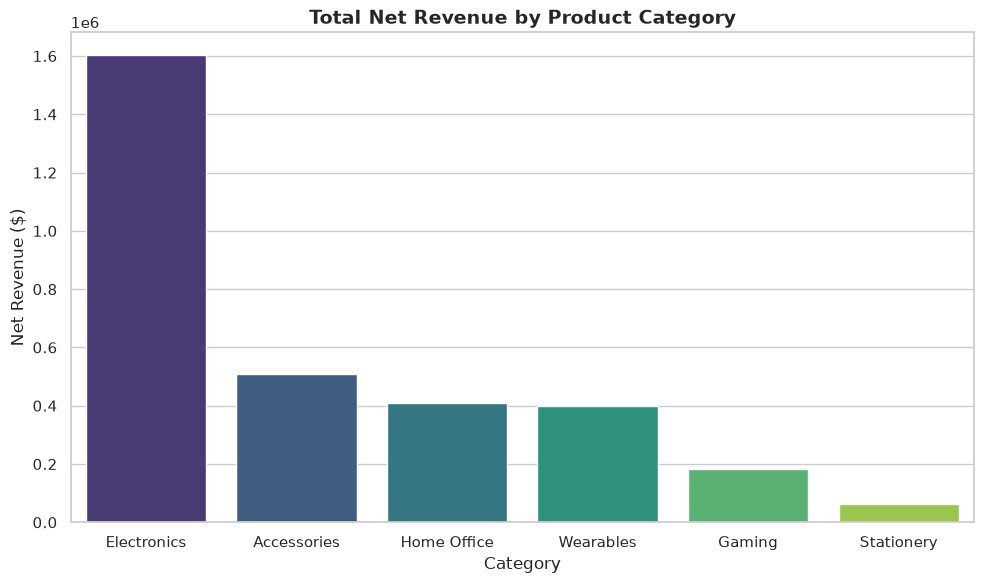

/tmp/ipykernel_18120/275731234.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_products, x='ProductName', y='Net_Revenue', palette='rocket')


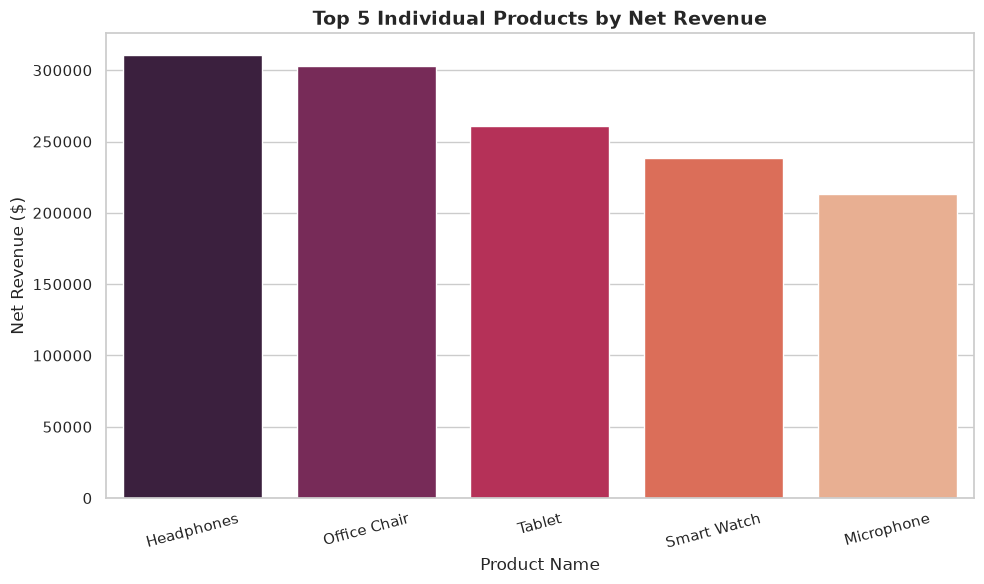

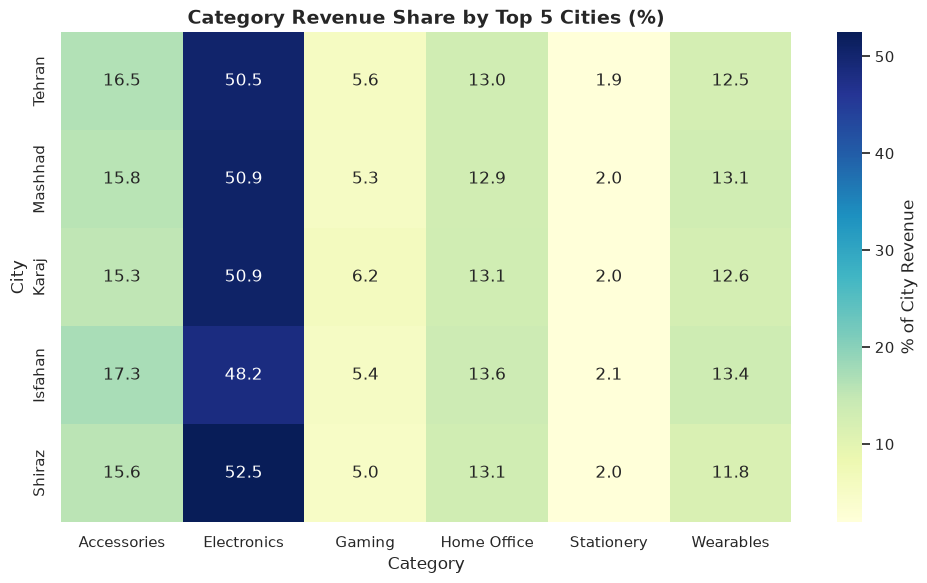

📊 RAW NUMBERS FOR YOUR REPORT

1. Top 5 Cities by Revenue:
   City  Net_Revenue
 Tehran     879739.0
Mashhad     404083.0
  Karaj     320889.0
Isfahan     308869.0
 Shiraz     289565.0

2. Revenue by Category:
   Category  Net_Revenue
Electronics    1601995.0
Accessories     509947.0
Home Office     410594.0
  Wearables     398152.0
     Gaming     181634.0
 Stationery      61442.0

3. Top 5 Individual Products:
 ProductName  Net_Revenue
  Headphones     310513.0
Office Chair     303192.0
      Tablet     260650.0
 Smart Watch     238716.0
  Microphone     213009.0

4. Regional Preference Snapshot (% of revenue per category in Top 3 Cities):
Category  Accessories  Electronics  Gaming  Home Office  Stationery  Wearables
City                                                                          
Tehran           16.5         50.5     5.6         13.0         1.9       12.5
Mashhad          15.8         50.9     5.3         12.9         2.0       13.1
Karaj            15.3         50.9

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD & QUICK CLEAN
df = pd.read_csv('clean_final_data.csv')
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

# Filter out invalid orders and calculate Net Revenue (Completed only)
df = df[df['Quantity'] > 0].copy()
df['Net_Revenue'] = np.where(df['Status'] == 'Completed', df['Sales'], 0.0)

# Set up plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# ==========================================
# ANALYSIS A: Revenue by City (Top 10)
# ==========================================
city_revenue = df.groupby('City')['Net_Revenue'].sum().reset_index()
city_revenue = city_revenue.sort_values(by='Net_Revenue', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=city_revenue, x='City', y='Net_Revenue', palette='mako')
plt.title('Top 10 Cities by Net Revenue', fontsize=14, fontweight='bold')
plt.xlabel('City', fontsize=12)
plt.ylabel('Net Revenue ($)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==========================================
# ANALYSIS B: Revenue by Category
# ==========================================
category_revenue = df.groupby('Category')['Net_Revenue'].sum().reset_index()
category_revenue = category_revenue.sort_values(by='Net_Revenue', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=category_revenue, x='Category', y='Net_Revenue', palette='viridis')
plt.title('Total Net Revenue by Product Category', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Net Revenue ($)', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# ANALYSIS C: Top 5 Individual Products by Revenue
# ==========================================
product_revenue = df.groupby('ProductName')['Net_Revenue'].sum().reset_index()
top_products = product_revenue.sort_values(by='Net_Revenue', ascending=False).head(5)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_products, x='ProductName', y='Net_Revenue', palette='rocket')
plt.title('Top 5 Individual Products by Net Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Product Name', fontsize=12)
plt.ylabel('Net Revenue ($)', fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# ==========================================
# ANALYSIS D: Regional Category Preference (Heatmap)
# ==========================================
# Create a pivot table: Cities as rows, Categories as columns, values as % of city revenue
city_category_pivot = df.groupby(['City', 'Category'])['Net_Revenue'].sum().unstack(fill_value=0)

# Normalize each row (city) to sum to 100% to see relative preference, not just absolute size
city_category_pct = city_category_pivot.div(city_category_pivot.sum(axis=1), axis=0) * 100

# Plot the top 5 cities to keep the heatmap readable
top_5_cities = city_revenue['City'].head(5).tolist()
heatmap_data = city_category_pct.loc[top_5_cities]

plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': '% of City Revenue'})
plt.title('Category Revenue Share by Top 5 Cities (%)', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('City', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# PRINT RAW NUMBERS FOR YOUR REPORT
# ==========================================
print("="*60)
print("📊 RAW NUMBERS FOR YOUR REPORT")
print("="*60)

print("\n1. Top 5 Cities by Revenue:")
print(city_revenue.head().to_string(index=False))

print("\n2. Revenue by Category:")
print(category_revenue.to_string(index=False))

print("\n3. Top 5 Individual Products:")
print(top_products.to_string(index=False))

print("\n4. Regional Preference Snapshot (% of revenue per category in Top 3 Cities):")
print(city_category_pct.loc[city_revenue['City'].head(3)].round(1).to_string())

💳 1. PAYMENT METHOD PERFORMANCE
PaymentMethod  Total_Orders  Net_Revenue  Avg_Order_Value  Total  Completion_Rate
   CardToCard         11739     757449.0            70.77  11739            92.08
         Cash          4921     317097.0            69.72   4921            92.05
      Gateway         23880    1534902.0            69.83  23880            91.96
       Wallet          8658     554316.0            69.80   8658            91.88


/tmp/ipykernel_18120/2001431678.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=payment_stats, x='PaymentMethod', y='Completion_Rate', palette='RdYlGn')


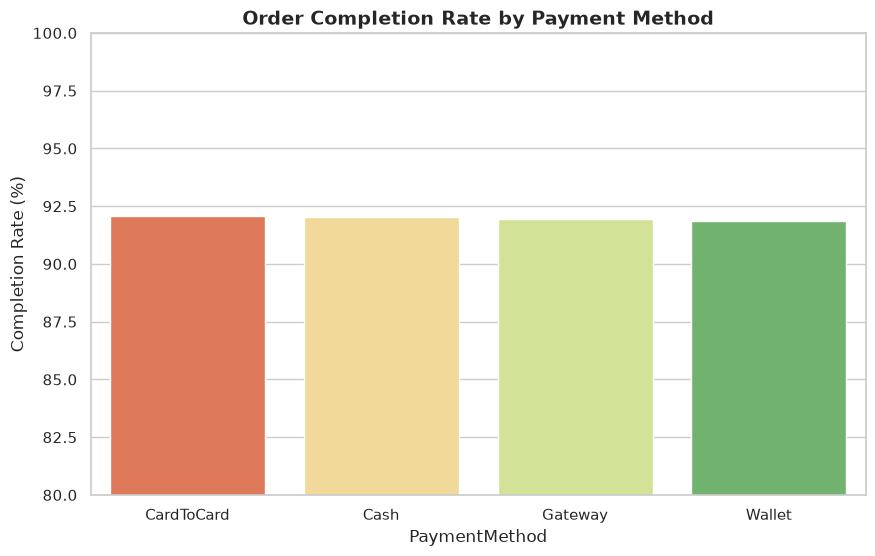


🔗 2. TOP 5 PRODUCT PAIRS (Frequently Bought Together)


/tmp/ipykernel_18120/2001431678.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['Status'] == 'Completed'], x='PaymentMethod', y='Sales', palette='pastel')


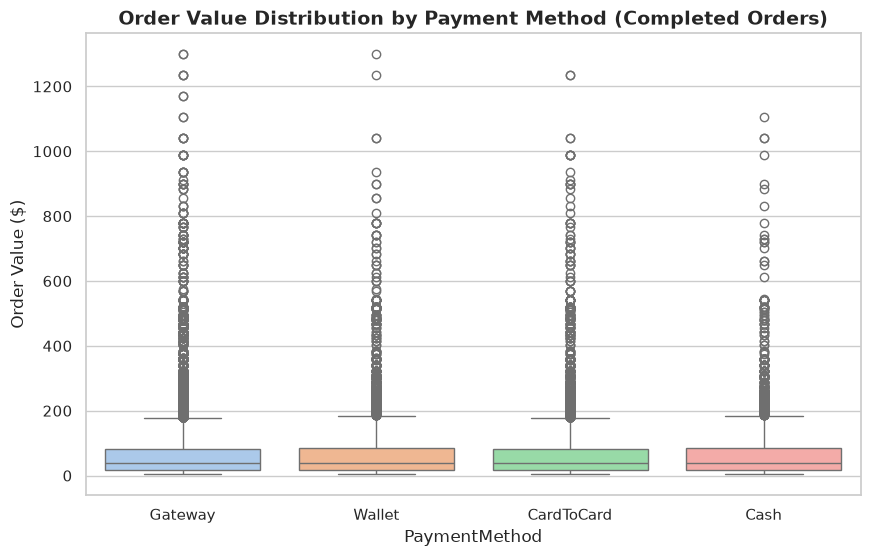


✅ Topic 4 Analysis Complete!


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter

# 1. LOAD & QUICK CLEAN
df = pd.read_csv('clean_final_data.csv')
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df = df[df['Quantity'] > 0].copy()
df['Net_Revenue'] = np.where(df['Status'] == 'Completed', df['Sales'], 0.0)

sns.set_theme(style="whitegrid")

# ==========================================
# ANALYSIS A: Payment Method Performance
# ==========================================
payment_stats = df.groupby('PaymentMethod').agg(
    Total_Orders=('OrderID', 'count'),
    Net_Revenue=('Net_Revenue', 'sum'),
    Avg_Order_Value=('Sales', 'mean')
).reset_index()

# Calculate completion rate per payment method
payment_status = df.groupby(['PaymentMethod', 'Status']).size().unstack(fill_value=0)
payment_status['Total'] = payment_status.sum(axis=1)
payment_status['Completion_Rate'] = (payment_status['Completed'] / payment_status['Total']) * 100

# Merge for a complete view
payment_stats = payment_stats.merge(payment_status[['Total', 'Completion_Rate']], left_on='PaymentMethod', right_index=True)

print("="*60)
print("💳 1. PAYMENT METHOD PERFORMANCE")
print("="*60)
print(payment_stats.round(2).to_string(index=False))

# Plot: Completion Rate by Payment Method
plt.figure(figsize=(10, 6))
sns.barplot(data=payment_stats, x='PaymentMethod', y='Completion_Rate', palette='RdYlGn')
plt.title('Order Completion Rate by Payment Method', fontsize=14, fontweight='bold')
plt.ylabel('Completion Rate (%)')
plt.ylim(80, 100) # Zoom in to see differences
plt.show()

# ==========================================
# ANALYSIS B: Simple Market Basket Analysis
# ==========================================
# Find orders with more than 1 item (either Quantity > 1 or multiple products per OrderID)
# For simplicity, we'll look at ProductName co-occurrence within the same OrderID
order_baskets = df[df['Status'] == 'Completed'].groupby('OrderID')['ProductName'].apply(list).reset_index()

# Filter to only baskets with 2 or more distinct items
multi_item_baskets = order_baskets[order_baskets['ProductName'].apply(lambda x: len(set(x)) > 1)]

# Generate pairs
pairs = []
for basket in multi_item_baskets['ProductName']:
    unique_items = list(set(basket))
    pairs.extend(list(combinations(unique_items, 2)))

# Count frequencies
pair_counts = Counter(pairs)
top_pairs = pair_counts.most_common(5)

print("\n" + "="*60)
print("🔗 2. TOP 5 PRODUCT PAIRS (Frequently Bought Together)")
print("="*60)
for i, (pair, count) in enumerate(top_pairs, 1):
    print(f"{i}. {pair[0]} + {pair[1]}  (Co-occurred in {count} orders)")

# ==========================================
# ANALYSIS C: AOV by Payment Method
# ==========================================
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[df['Status'] == 'Completed'], x='PaymentMethod', y='Sales', palette='pastel')
plt.title('Order Value Distribution by Payment Method (Completed Orders)', fontsize=14, fontweight='bold')
plt.ylabel('Order Value ($)')
plt.show()

print("\n✅ Topic 4 Analysis Complete!")

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter

# 1. LOAD & QUICK CLEAN
df = pd.read_csv('clean_final_data.csv')
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df = df[df['Quantity'] > 0].copy()
df['Net_Revenue'] = np.where(df['Status'] == 'Completed', df['Sales'], 0.0)

sns.set_theme(style="whitegrid")

# ==========================================
# ANALYSIS A: Payment Method Performance
# ==========================================
payment_stats = df.groupby('PaymentMethod').agg(
    Total_Orders=('OrderID', 'count'),
    Net_Revenue=('Net_Revenue', 'sum'),
    Avg_Order_Value=('Sales', 'mean')
).reset_index()

# Calculate completion rate per payment method
payment_status = df.groupby(['PaymentMethod', 'Status']).size().unstack(fill_value=0)
payment_status['Total'] = payment_status.sum(axis=1)
payment_status['Completion_Rate'] = (payment_status['Completed'] / payment_status['Total']) * 100

payment_stats = payment_stats.merge(payment_status[['Total', 'Completion_Rate']], left_on='PaymentMethod', right_index=True)

print("="*60)
print("💳 1. PAYMENT METHOD PERFORMANCE")
print("="*60)
print(payment_stats.round(2).to_string(index=False))

# ==========================================
# ANALYSIS B: Simple Market Basket Analysis
# ==========================================
# Find orders with more than 1 distinct item
order_baskets = df[df['Status'] == 'Completed'].groupby('OrderID')['ProductName'].apply(list).reset_index()
multi_item_baskets = order_baskets[order_baskets['ProductName'].apply(lambda x: len(set(x)) > 1)]

# Generate pairs and count frequencies
pairs = []
for basket in multi_item_baskets['ProductName']:
    unique_items = list(set(basket))
    pairs.extend(list(combinations(unique_items, 2)))

pair_counts = Counter(pairs)
top_pairs = pair_counts.most_common(5)

print("\n" + "="*60)
print("🔗 2. TOP 5 PRODUCT PAIRS (Frequently Bought Together)")
print("="*60)
for i, (pair, count) in enumerate(top_pairs, 1):
    print(f"{i}. {pair[0]} + {pair[1]}  (Co-occurred in {count} orders)")

print("\n✅ Topic 4 Analysis Complete!")

💳 1. PAYMENT METHOD PERFORMANCE
PaymentMethod  Total_Orders  Net_Revenue  Avg_Order_Value  Total  Completion_Rate
   CardToCard         11739     757449.0            70.77  11739            92.08
         Cash          4921     317097.0            69.72   4921            92.05
      Gateway         23880    1534902.0            69.83  23880            91.96
       Wallet          8658     554316.0            69.80   8658            91.88

🔗 2. TOP 5 PRODUCT PAIRS (Frequently Bought Together)

✅ Topic 4 Analysis Complete!


In [28]:
import pandas as pd
import numpy as np
from scipy import stats

# 1. Load Data
df = pd.read_csv('clean_final_data.csv')
df = df[df['Quantity'] > 0].copy()

# 2. Simplify the variables for the test
# Did they get a discount? (True/False)
df['Has_Discount'] = df['Discount'] > 0 

# Was the order successful? (True for Completed, False for Cancelled/Returned)
df['Is_Completed'] = df['Status'] == 'Completed'

# 3. Create a Contingency Table (Cross-tabulation)
# This shows the raw counts of the 4 possible outcomes
contingency_table = pd.crosstab(df['Has_Discount'], df['Is_Completed'])
print("--- CONTINGENCY TABLE (Raw Counts) ---")
print(contingency_table)
print("\n")

# 4. Run the Chi-Square Test
chi2_stat, p_value, dof, expected = stats.chi2_contingency(contingency_table)

print("--- STATISTICAL TEST RESULTS ---")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"P-Value: {p_value:.4f}")

# 5. The Business Decision
alpha = 0.05 # Standard 95% confidence level
print("\n--- THE VERDICT ---")
if p_value < alpha:
    print("✅ REJECT the Null Hypothesis.")
    print("Conclusion: Discounts DO have a statistically significant impact on completion rates.")
else:
    print("❌ FAIL TO REJECT the Null Hypothesis.")
    print("Conclusion: The difference in completion rates is just random noise.")
    print("Action: We can safely reduce blanket discounts without fearing a massive drop in completions!")

--- CONTINGENCY TABLE (Raw Counts) ---
Is_Completed  False  True 
Has_Discount              
False          1398  15944
True           2547  29309


--- STATISTICAL TEST RESULTS ---
Chi-Square Statistic: 0.0577
P-Value: 0.8102

--- THE VERDICT ---
❌ FAIL TO REJECT the Null Hypothesis.
Conclusion: The difference in completion rates is just random noise.
Action: We can safely reduce blanket discounts without fearing a massive drop in completions!


Index(['Recency', 'Frequency', 'Monetary', 'ML_Cluster'], dtype='str')
--- 🤖 MACHINE LEARNING CLUSTER PROFILES ---
            Recency  Frequency  Monetary
ML_Cluster                              
0             138.3        6.4     341.5
1             156.4        3.6     171.6
2             491.0        3.0     180.2
3             131.6        7.4     724.2


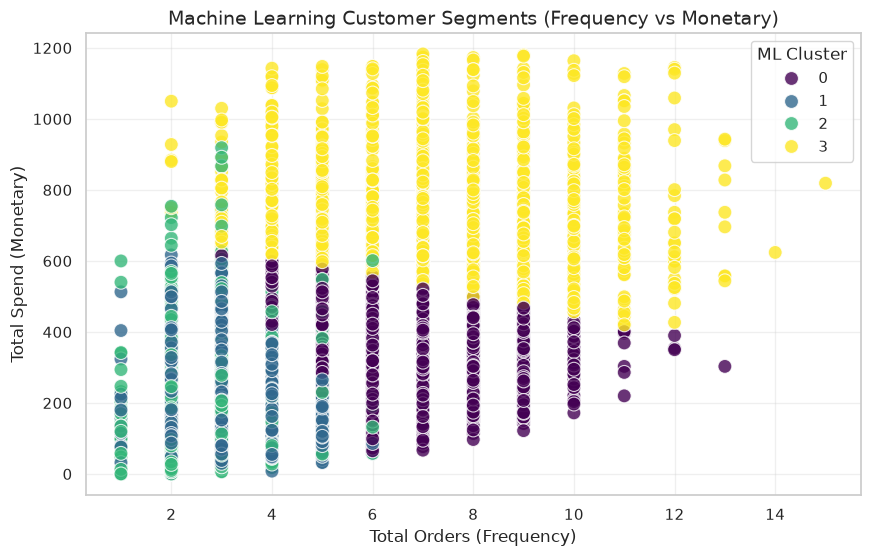

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load & Clean Data
df = pd.read_csv('clean_final_data.csv')
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df = df[df['Quantity'] > 0].copy()
df['Net_Revenue'] = np.where(df['Status'] == 'Completed', df['Sales'], 0.0)

# 2. Calculate RFM Metrics per Customer
# Snapshot date is the day after the last order in our dataset
snapshot_date = df['OrderDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'OrderDate': lambda x: (snapshot_date - x.max()).days, # Recency
    'OrderID': 'count',                                    # Frequency
    'Net_Revenue': 'sum'                                   # Monetary
}).rename(columns={'OrderDate': 'Recency', 'OrderID': 'Frequency', 'Net_Revenue': 'Monetary'})

# Filter out extreme outliers so they don't break the ML model
rfm = rfm[rfm['Monetary'] < rfm['Monetary'].quantile(0.99)]

# 3. Scale the Data (CRITICAL FOR MACHINE LEARNING)
# Why? Monetary is in thousands (e.g., 5000), Frequency is in single digits (e.g., 3).
# ML calculates "distance". If we don't scale, Monetary will dominate the algorithm.
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

# 4. Run K-Means Clustering
# Let's ask the ML model to find 4 distinct behavioral groups
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['ML_Cluster'] = kmeans.fit_predict(rfm_scaled)
print(rfm.columns)


# 5. Analyze the ML's Discoveries
cluster_summary = rfm.groupby('ML_Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    # Number of customers in this cluster
}).round(1)

print("--- 🤖 MACHINE LEARNING CLUSTER PROFILES ---")
print(cluster_summary)

# 6. Visualize the Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(data=rfm, x='Frequency', y='Monetary', hue='ML_Cluster', palette='viridis', s=100, alpha=0.8)
plt.title('Machine Learning Customer Segments (Frequency vs Monetary)', fontsize=14)
plt.xlabel('Total Orders (Frequency)')
plt.ylabel('Total Spend (Monetary)')
plt.legend(title='ML Cluster')
plt.grid(True, alpha=0.3)
plt.show()